# Rossmann Store Sales. Разбор результатов

Проверяем, помогает ли история продаж точнее прогнозировать дневную выручку.
Результаты для ноутбука готовит команда `python -m src.run_baseline` из корня проекта.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
config = json.loads((root / "configs/baseline.json").read_text(encoding="utf-8"))
output = root / config["output_dir"]
report = json.loads((output / "metrics.json").read_text(encoding="utf-8"))
predictions = pd.read_csv(output / "predictions.csv", parse_dates=["Date"])
scored = predictions.loc[predictions["Sales"] > 0].copy()

plt.style.use("seaborn-v0_8-whitegrid")

## Что есть в данных

Одна строка в таблице описывает один день одного магазина. Если `Open = 0`, магазин в этот день не работал, поэтому его выручка равна нулю. В данных есть и 54 случая, когда магазин был открыт, а выручка записана как нулевая.

По правилам контеста RMSPE считаем только для дней с положительной выручкой. На графиках ниже тоже берем только такие дни.

У 180 магазинов с июля по декабрь 2014 года вообще нет записей. Из-за этого для некоторых дат нельзя взять выручку за тот же день недели год назад.

,Значение
Дни всех магазинов,1017209
Магазины,1115
Начало,2013-01-01
Конец,2015-07-31
Пустые ячейки в имеющихся строках,0
Строки с нулевой выручкой,172871
"Дни, когда магазин не работал",172817
Дни работы с нулевой выручкой,54


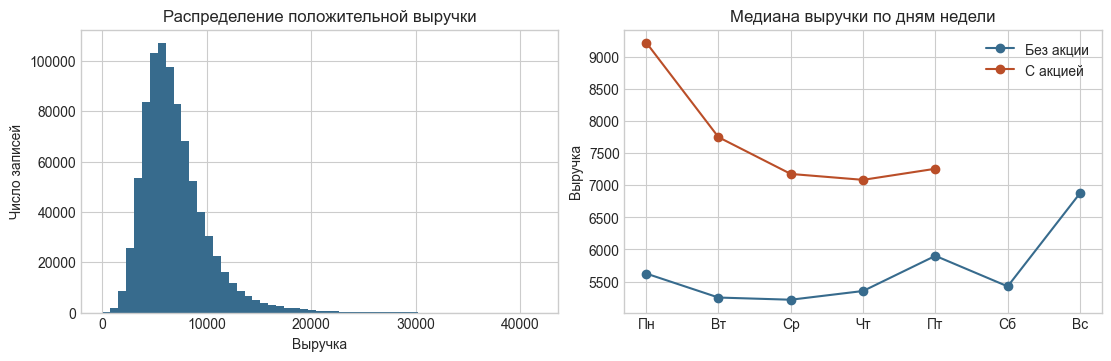

In [2]:
data = report["data"]
display(pd.Series({
    "Дни всех магазинов": data["rows"],
    "Магазины": data["stores"],
    "Начало": data["first_date"],
    "Конец": data["last_date"],
    "Пустые ячейки в имеющихся строках": sum(data["missing"].values()),
    "Строки с нулевой выручкой": data["zero_sales"],
    "Дни, когда магазин не работал": data["closed_days"],
    "Дни работы с нулевой выручкой": data["open_zero_sales"],
}, name="Значение").to_frame())

sales = pd.read_csv(
    root / config["data_path"],
    usecols=["Store", "Date", "Sales", "DayOfWeek", "Promo"],
    parse_dates=["Date"],
)
positive = sales.loc[sales["Sales"] > 0]
by_day = positive.groupby(["DayOfWeek", "Promo"])["Sales"].median().unstack()
by_day.index = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_day.columns = ["Без акции", "С акцией"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(positive["Sales"], bins=55, color="#376b8d")
axes[0].set(title="Распределение положительной выручки", xlabel="Выручка", ylabel="Число записей")
by_day.plot(ax=axes[1], marker="o", color=["#376b8d", "#ba4e28"])
axes[1].set(title="Медиана выручки по дням недели", xlabel="", ylabel="Выручка")
plt.show()

На графике слева около 93% положительных значений дневной выручки лежат между 2000 и 12 000. Половина значений ниже 6369.

Справа сравниваем дни с акциями и без них. Например, по понедельникам медиана выручки составляет 5625 без акции и 9225 с акцией. В выходные в данных с положительной выручкой нет записей об акциях, поэтому оранжевая линия заканчивается на пятнице.

## Три исследовательских вопроса

1. Помогает ли информация о тренде?
2. Добавляют ли прошлогодние продажи полезную информацию?
3. Насколько прогноз чувствителен к разовым всплескам в истории?

## Трейн и валидация

| Набор | Даты | Для чего используем |
|---|---|---|
| Трейн | Со 2 марта 2013 по 19 июня 2015 | Обучаем модели. Продажи до 2 марта нужны для расчета первых исторических признаков |
| Валидация | С 20 июня по 31 июля 2015 | Проверяем гипотезу и исследовательские вопросы, считаем ошибки и интервалы |

Трейн и один период валидации выделены из `train.csv`.

## Как сравниваем модели

Обе версии линейной регрессии используют номер магазина, день недели, месяц и запланированную акцию. Второй версии дополнительно даем девять признаков из прошлых продаж. Тренд считаем как наклон недельных средних за восемь недель после экспоненциального сглаживания. Еще используем выручку за 28 дней до прогноза, разброс за восемь недель и недавнюю медиану по нужному дню недели.

При обучении логарифмируем выручку. На этой шкале промах на 1000 при выручке 2000 весит больше, чем такой же промах при выручке 20 000. Для расчета RMSPE и MAE переводим прогноз обратно в единицы выручки.

Сравниваем прогнозы на одних и тех же днях с положительной выручкой. В момент прогноза считаем акции и дни работы магазина известными на все шесть недель.

### Как проверяем исследовательские вопросы

1. Тренд. Сравниваем полную модель с версией без тренда. Считаем RMSPE и MAE на всех днях с положительной выручкой в основном периоде.
2. Продажи год назад. Сравниваем полную модель с версией без выручки за дату 364 дня назад. Берем только строки, для которых эта запись есть.
3. Всплески. В истории до валидации отмечаем дни с выручкой не меньше трех медиан для магазина и дня недели. Берем магазины, где такие дни есть и составляют не больше 1% дней с продажами. Удаляем всплески из копии истории и пересчитываем признаки. Если удаленная строка давала выручку год назад, подставляем среднюю выручку этого магазина за тот же день недели по оставшимся дням с продажами. Сравниваем прогнозы, RMSPE и MAE одной обученной модели на тех же днях валидации. На исходной истории отдельно сравниваем среднее и медиану.

### Как считаем бутстрап-интервалы

Считаем разницу в RMSPE между двумя вариантами на одних и тех же магазинах и датах. Отрицательная разница означает, что второй вариант уменьшил ошибку.

В каждом из 1000 повторов случайно выбираем магазины с возможностью повторов. Для каждого берем сразу все дни, а для обоих вариантов используем один и тот же набор магазинов. Поправка Бонферрони расширяет интервалы с учетом четырех сравнений. Это снижает шанс принять случайную разницу за эффект. Если интервал не содержит ноль, считаем различие статистически значимым при общем уровне 5%.

Оценка относится к выбранным магазинам на последних 42 днях. Она отражает, насколько результат меняется при другом составе магазинов в этом периоде.

,Дни с выручкой,"RMSPE, %",MAE
Без истории,40282.0,20.33,931.78
С историей,40282.0,15.64,746.86


На сколько снизился RMSPE: 23.05%
95%-й бутстрап-интервал для снижения: от 21.05% до 24.93%


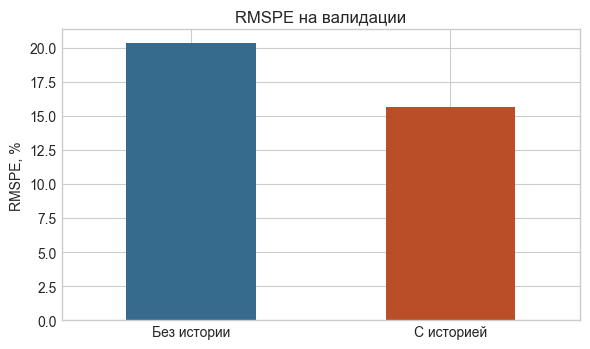

In [3]:
names = {"no_history": "Без истории", "with_history": "С историей"}
main = pd.DataFrame({names[key]: report["experiments"][key] for key in names}).T
main["rmspe"] *= 100
display(main.rename(columns={"rows": "Дни с выручкой", "rmspe": "RMSPE, %", "mae": "MAE"}).round(2))

improvement = report["relative_improvement"] * 100
lower, upper = [bound * 100 for bound in report["bootstrap_95_ci"]]
print(f"На сколько снизился RMSPE: {improvement:.2f}%")
print(f"95%-й бутстрап-интервал для снижения: от {lower:.2f}% до {upper:.2f}%")

ax = main["rmspe"].plot(kind="bar", figsize=(6, 3.6), color=["#376b8d", "#ba4e28"], rot=0)
ax.set(title="RMSPE на валидации", xlabel="", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

На валидации история продаж снизила RMSPE на 23,05% при согласованном пороге 5%. Бутстрап показывает, насколько результат зависит от состава магазинов на этих датах.

## Где модель ошибается

Сначала выделяем 10% дней с самой низкой положительной выручкой. Остальные дни делим на две группы, с акцией и без акции. Считаем ошибку для каждой группы.

Как часто завышаем прогноз в дни с низкой выручкой: 77.2%
Доля таких дней в сумме квадратов относительных ошибок: 32.9%


,Дни с выручкой,Без истории,С историей
Группа дней,,,
Низкая выручка,4029,42.90,28.39
Дни с акцией,16427,15.42,13.51
Дни без акции,19826,16.39,13.50


,Группа дней,Магазин,Дата,Факт,Прогноз,"Ошибка, %"
0,Низкая выручка,5,2015-06-20,2088,2974,42.4
1,Дни с акцией,551,2015-07-30,6429,7825,21.7
2,Дни без акции,455,2015-07-23,7269,5757,-20.8


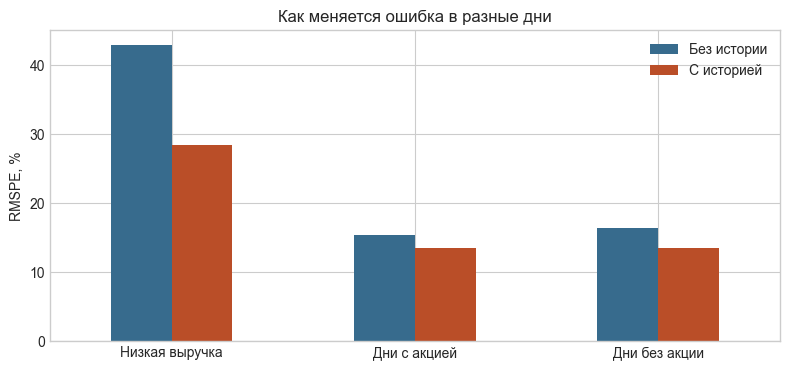

In [4]:
low = scored["Sales"] <= scored["Sales"].quantile(0.10)
groups = {
    "Низкая выручка": scored.loc[low],
    "Дни с акцией": scored.loc[~low & scored["Promo"].eq(1)],
    "Дни без акции": scored.loc[~low & scored["Promo"].eq(0)],
}

slices = []
examples = []
for label, rows in groups.items():
    errors = rows[list(names)].sub(rows["Sales"], axis=0).div(rows["Sales"], axis=0)
    rmspe = errors.pow(2).mean().pow(0.5).mul(100)
    slices.append({"Группа дней": label, "Дни с выручкой": len(rows), **rmspe.rename(names).to_dict()})
    relative = errors["with_history"].abs()
    example = rows.loc[(relative - relative.quantile(0.9)).abs().idxmin()]
    examples.append({
        "Группа дней": label,
        "Магазин": example["Store"],
        "Дата": example["Date"].date(),
        "Факт": example["Sales"],
        "Прогноз": round(example["with_history"]),
        "Ошибка, %": round(100 * (example["with_history"] / example["Sales"] - 1), 1),
    })

by_slice = pd.DataFrame(slices).set_index("Группа дней")
signed_error = scored["with_history"] / scored["Sales"] - 1
overprediction = signed_error.loc[low].gt(0).mean()
error_share = signed_error.loc[low].pow(2).sum() / signed_error.pow(2).sum()
print(f"Как часто завышаем прогноз в дни с низкой выручкой: {overprediction:.1%}")
print(f"Доля таких дней в сумме квадратов относительных ошибок: {error_share:.1%}")
display(by_slice.round(2))
display(pd.DataFrame(examples))
ax = by_slice[list(names.values())].plot(
    kind="bar", rot=0, figsize=(8, 3.8), color=["#376b8d", "#ba4e28"]
)
ax.set(title="Как меняется ошибка в разные дни", xlabel="", ylabel="RMSPE, %")
plt.tight_layout()
plt.show()

Из каждой группы взяли по одному примеру, где ошибка модели с историей была больше, чем примерно в 90% случаев в этой группе. Посмотрим, какими были продажи этого магазина в прошлом.

In [5]:
cutoff = pd.Timestamp(report["validation"]["start"])
prior = sales.loc[sales["Date"].lt(cutoff)]
context = []
for example in examples:
    store_id = example["Магазин"]
    day = pd.Timestamp(example["Дата"])
    row = scored.loc[scored["Store"].eq(store_id) & scored["Date"].eq(day)].iloc[0]
    store_past = prior.loc[prior["Store"].eq(store_id)]
    positive_past = store_past.loc[store_past["Sales"].gt(0)]
    same_weekday = positive_past.loc[positive_past["DayOfWeek"].eq(row["DayOfWeek"])]
    same_promo = same_weekday.loc[same_weekday["Promo"].eq(row["Promo"])]
    recent_weekdays = same_weekday.loc[same_weekday["Date"].ge(cutoff - pd.Timedelta(weeks=8))]
    recent_same_promo = recent_weekdays.loc[recent_weekdays["Promo"].eq(row["Promo"])]
    last_year_date = day - pd.Timedelta(days=config["year_lag_days"])
    last_year = store_past.loc[store_past["Date"].eq(last_year_date), "Sales"]
    last_28 = positive_past.loc[positive_past["Date"].ge(cutoff - pd.Timedelta(days=28))]
    context.append({
        "Магазин": store_id,
        "Дата": day.date(),
        "Типичная выручка в этот день недели при том же промо": same_promo["Sales"].median(),
        "Средняя выручка за 28 дней": last_28["Sales"].mean(),
        "Продажи год назад": last_year.iloc[0] if len(last_year) else None,
        "Медиана недавних таких дней": recent_weekdays["Sales"].median(),
        "Медиана недавних таких дней при том же промо": recent_same_promo["Sales"].median(),
        "Недавних таких дней с акциями": recent_weekdays["Promo"].sum(),
        "Недавних таких дней всего": len(recent_weekdays),
    })
display(pd.DataFrame(context).round(1))

,Магазин,Дата,Типичная выручка в этот день недели при том же промо,Средняя выручка за 28 дней,Продажи год назад,Медиана недавних таких дней,Медиана недавних таких дней при том же промо,Недавних таких дней с акциями,Недавних таких дней всего
0,5,2015-06-20,2000.5,4812.4,1816,2153.5,2153.5,0,8
1,551,2015-07-30,6537.5,6855.3,10644,6658.0,6712.0,5,7
2,455,2015-07-23,5478.0,8242.7,5849,7471.0,6154.5,4,6


- Магазин 5. Обычная суббота без акции приносила примерно 2001. В день ошибки выручка была 2088. Общий уровень магазина за последние 28 дней заметно выше, в среднем 4812. Возможно, модель дала этому уровню слишком большой вес для субботы.
- Магазин 551. Фактические 6429 близки к типичному четвергу с акцией, 6538. За соответствующую дату год назад выручка была 10 644. Это могло подтянуть прогноз вверх.
- Магазин 475. Пять из семи недавних понедельников были с акцией. Общая медиана равна 8547, а для двух понедельников без акции она равна 5623. В день ошибки акции не было и выручка составила 5035. Общая медиана могла завысить прогноз.

На графике ниже сравниваем фактическую выручку магазина 1 с прогнозами. Линии опускаются до нуля в дни, когда магазин не работал.

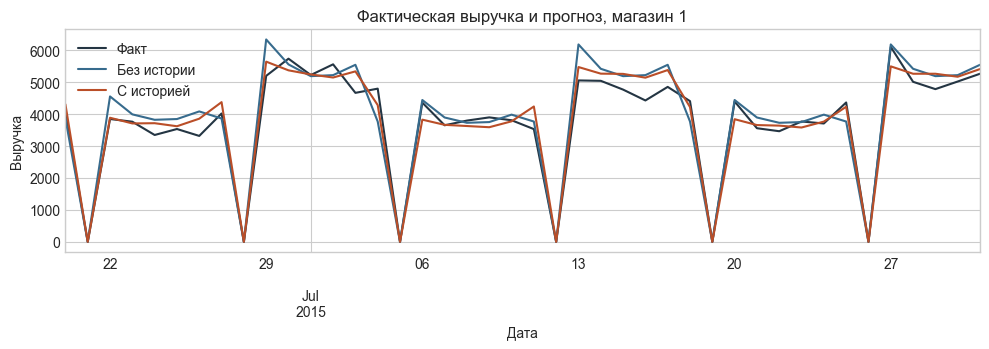

In [6]:
store_id = predictions["Store"].min()
store = predictions.loc[predictions["Store"] == store_id].sort_values("Date").set_index("Date")
lines = store[["Sales", "no_history", "with_history"]].rename(columns={"Sales": "Факт", **names})
ax = lines.plot(figsize=(10, 3.6), color=["#243543", "#376b8d", "#ba4e28"])
ax.set(title=f"Фактическая выручка и прогноз, магазин {store_id}", xlabel="Дата", ylabel="Выручка")
plt.tight_layout()
plt.show()

## Ответы на исследовательские вопросы

In [7]:
uncertainty = report["comparison_uncertainty"]["comparisons"]

def interval_text(item):
    low, high = item["interval"]
    return f"{100 * low:+.3f} до {100 * high:+.3f}"

labels = {
    "trend": "Без тренда / с трендом",
    "last_year": "Без прошлого года / с прошлым годом",
    "spikes": "Среднее / медиана для магазинов со всплесками",
}
checks = []
for key, label in labels.items():
    first, second = report["research_checks"][key].values()
    checks.append({
        "Сравнение": label,
        "Дни с выручкой": first["rows"],
        "RMSPE варианта 1, %": first["rmspe"] * 100,
        "RMSPE варианта 2, %": second["rmspe"] * 100,
        "Изменение, п.п.": 100 * uncertainty[key]["delta_rmspe"],
        "Интервал, п.п.": interval_text(uncertainty[key]),
    })
display(pd.DataFrame(checks).round(3))

,Сравнение,Дни с выручкой,"RMSPE варианта 1, %","RMSPE варианта 2, %","Изменение, п.п.","Интервал, п.п."
0,Без тренда / с трендом,40282,15.494,15.643,0.149,+0.125 до +0.174
1,Без прошлого года / с прошлым годом,35252,16.313,15.617,-0.696,-0.769 до -0.621
2,Среднее / медиана для магазинов со всплесками,1363,20.310,20.397,0.087,-0.352 до +0.440


Сглаженный тренд повысил RMSPE с 15,49% до 15,64%. Прошлогодняя выручка снизила его с 16,31% до 15,62% на днях, для которых известна. Оба доверительных интервала исключают ноль.

У 38 магазинов со всплесками среднее дало чуть меньший RMSPE, чем медиана. Доверительный интервал для этой разницы содержит ноль.

,Дни с выручкой,"RMSPE, %",MAE
История со всплесками,1363.0,20.397,712.405
Без всплесков,1363.0,20.324,709.600


Убрали всплесков из истории: 55
Прошлогоднюю выручку заменили средним в 4 прогнозах
Изменение RMSPE: -0.073 п.п. Интервал: -0.228 до +0.007 п.п.
Половина прогнозов изменилась не более чем на 1.5
90% прогнозов изменились не более чем на 9.7


,Store,Date,Sales,with_history,history_without_spikes
26836,303,2015-07-14,7797,9482.7,7153.3


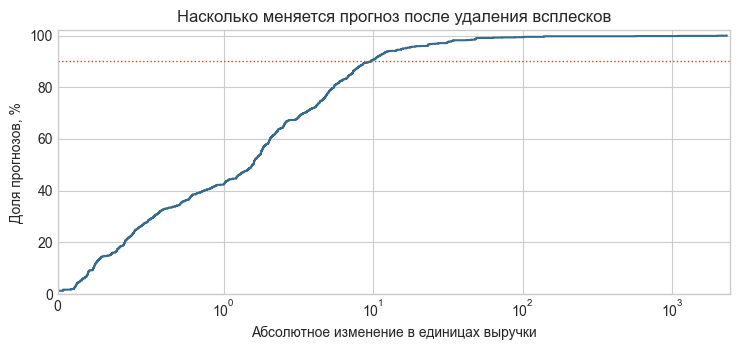

In [8]:
stress = report["spike_sensitivity"]
comparison = pd.DataFrame({
    "История со всплесками": stress["original"],
    "Без всплесков": stress["without_spikes"],
}).T
comparison["rmspe"] *= 100
display(comparison.rename(columns={"rows": "Дни с выручкой", "rmspe": "RMSPE, %", "mae": "MAE"}).round(3))

print(f'Убрали всплесков из истории: {stress["removed_rows"]}')
print(f'Прошлогоднюю выручку заменили средним в {stress["replaced_last_year_scored_rows"]} прогнозах')
change_result = uncertainty["remove_spikes"]
print(f'Изменение RMSPE: {100 * change_result["delta_rmspe"]:+.3f} п.п. Интервал: {interval_text(change_result)} п.п.')
print(f'Половина прогнозов изменилась не более чем на {stress["median_absolute_change"]:.1f}')
print(f'90% прогнозов изменились не более чем на {stress["p90_absolute_change"]:.1f}')

changed = scored.dropna(subset=["history_without_spikes"])
change = (changed["history_without_spikes"] - changed["with_history"]).abs().sort_values()
largest = changed.loc[[change.idxmax()], ["Store", "Date", "Sales", "with_history", "history_without_spikes"]]
display(largest.round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
share = 100 * change.rank(method="max", pct=True)
ax.step(change, share, where="post", color="#376b8d")
ax.axhline(90, color="#ba4e28", linestyle=":", linewidth=1)
ax.set_xscale("symlog", linthresh=1)
ax.set(
    xlim=(0, None),
    ylim=(0, 102),
    title="Насколько меняется прогноз после удаления всплесков",
    xlabel="Абсолютное изменение в единицах выручки",
    ylabel="Доля прогнозов, %",
)
plt.tight_layout()
plt.show()

После удаления 55 всплесков половина прогнозов изменилась не больше чем на 1,5 единицы выручки, а 90% изменились не больше чем на 9,7. RMSPE снизился с 20,40% до 20,32%, MAE с 712,41 до 709,60. Интервал для изменения RMSPE содержит ноль.

Сильнее всего изменился прогноз магазина 303 на 14 июля. После удаления всплеска вместо прошлогодней выручки 27 318 подставили среднее 6332. Прогноз снизился с 9483 до 7153 при фактической выручке 7797.

### Интервалы для исследовательских вопросов

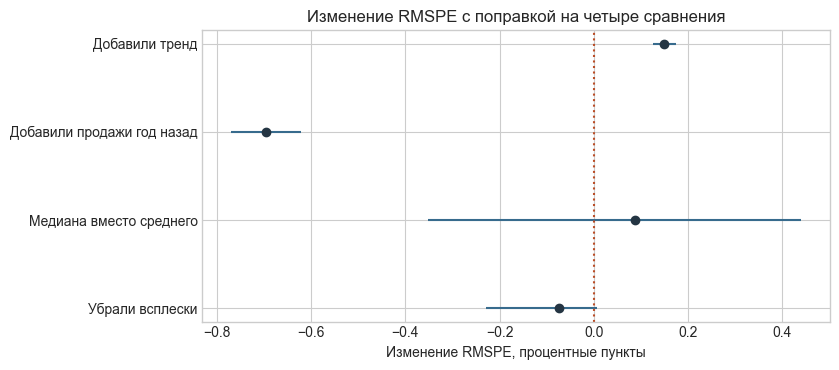

In [9]:
labels = {
    "trend": "Добавили тренд",
    "last_year": "Добавили продажи год назад",
    "spikes": "Медиана вместо среднего",
    "remove_spikes": "Убрали всплески",
}

comparisons = []
for name, label in labels.items():
    item = uncertainty[name]
    low, high = item["interval"]
    comparisons.append({
        "Сравнение": label,
        "Изменение RMSPE, п.п.": 100 * item["delta_rmspe"],
        "Нижняя граница": 100 * low,
        "Верхняя граница": 100 * high,
    })
intervals = pd.DataFrame(comparisons)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
positions = range(len(intervals))
ax.hlines(positions, intervals["Нижняя граница"], intervals["Верхняя граница"], color="#376b8d")
ax.scatter(intervals["Изменение RMSPE, п.п."], positions, color="#243543", zorder=3)
ax.axvline(0, color="#ba4e28", linestyle=":")
ax.set_yticks(list(positions), labels=intervals["Сравнение"])
ax.invert_yaxis()
ax.set(
    title="Изменение RMSPE с поправкой на четыре сравнения",
    xlabel="Изменение RMSPE, процентные пункты",
)
plt.tight_layout()
plt.show()

## Вывод

История продаж снизила RMSPE больше чем на 5% на валидации. Из отдельно проверенных признаков сильнее всего помогла выручка год назад. Самые большие относительные ошибки остались в дни с низкими продажами.